## Random Forest 

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit

import pandas as pd
import numpy as np
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris

In [ ]:
file_path = "/home/callum/projects/sno_analysis/data/processed"
file = "df_for_regression.csv"

df = pd.read_csv(os.path.join(file_path, file))
df = df.iloc[:, 1:]
print(df.head())

       id  modified  position                                   sequence  \
0  Q9Y2Z0         1        88  AKKSLELNPNNSTAMLRKGICEYHEKNYAAALETFTEGQKL   
1  Q14584         0       441  SNLSGHLRIHTGEKPFECLECGKAFTHSSSLNNHMRTHSAK   
2  P00390         0       328  SMVTAVPGRLPVMTMIPDVDCLLWAIGRVPNTKDLSLNKLG   
3  Q5UIP0         0      1735  TLECQHKRSRRVRRSKGCDCCGEKSQPQEKSLIGLKNTENN   
4  P0C8J8         0        17  ----MKTLIARHKAGEHIGICSVCSAHPLVIEAALAFDRNS   

   hydrophobicity_5  hydrophobicity_10  charge_5  charge_10  cluster_id  \
0             -15.9              -16.6       1.0        1.0       791.0   
1               1.7              -10.2      -1.0       -1.0       449.0   
2              13.1               13.0      -2.0       -1.0       491.0   
3             -14.9              -38.3       0.0        3.0        21.0   
4               8.8                6.3      -1.0        1.0       677.0   

   pwm_pos_-3  pwm_pos_-2  pwm_pos_-1  pwm_pos_+1  pwm_pos_+2  pwm_pos_+3  
0   -0.211967   

In [18]:
#df = pd.read_csv("/home/callum/projects/ub_predictor/data/processed/20261001_154827_sites_test/features_complete_readable.csv")
print(df.head())

  uniprot_id  lysine_position  modified region_type  \
0     Q9Y2Z0               88         1  structured   
1     Q14584              441         0  structured   
2     P00390              328         0  structured   
3     P0C8J8               17         0  structured   
4     Q9Z1G4              730         0  structured   

   position_in_protein_fraction  distance_from_n_terminus_residues  \
0                        0.2411                                 88   
1                        0.8033                                441   
2                        0.6284                                328   
3                        0.0405                                 17   
4                        0.8701                                730   

   distance_from_c_terminus_residues  protein_length_residues  \
0                                277                      365   
1                                108                      549   
2                                194                 

In [11]:
print(df["modified"].value_counts())

modified
0    4112
1     835
Name: count, dtype: int64


# cluster by IDs prior to splitting
# / data preparation

In [5]:
df = df.dropna()

# get feature columns
feature_cols = "hydrophobicity_5  hydrophobicity_10  charge_5  charge_10  pwm_pos_-3  pwm_pos_-2  pwm_pos_-1  pwm_pos_+1  pwm_pos_+2  pwm_pos_+3"
feature_cols = feature_cols.split("  ")

df["modified"] = df.modified
print(feature_cols)

['hydrophobicity_5', 'hydrophobicity_10', 'charge_5', 'charge_10', 'pwm_pos_-3', 'pwm_pos_-2', 'pwm_pos_-1', 'pwm_pos_+1', 'pwm_pos_+2', 'pwm_pos_+3']


In [14]:
# using train_test_split instead
y=df['modified']
cols = df.columns
met_cols = cols.drop(["uniprot_id", "modified", "lysine_position"])
X= df[met_cols]

print(y, X)


# using the train test split function
X_train, X_test, y_train, y_test = train_test_split(X,y ,
                                   random_state=104, 
                                   test_size=0.25, 
                                   shuffle=True)


print(y_train.value_counts())
print(y_test.value_counts())

0      1
1      0
2      0
3      0
4      0
      ..
387    1
388    0
389    0
390    1
391    0
Name: modified, Length: 380, dtype: int64     region_type  position_in_protein_fraction  \
0    structured                        0.2411   
1    structured                        0.8033   
2    structured                        0.6284   
3    structured                        0.0405   
4    structured                        0.8701   
..          ...                           ...   
387  structured                        0.7434   
388  structured                        0.8776   
389  structured                        0.0177   
390  structured                        0.5585   
391  structured                        0.2962   

     distance_from_n_terminus_residues  distance_from_c_terminus_residues  \
0                                   88                                277   
1                                  441                                108   
2                                  328 

In [17]:

# group shuffle split does the split ratio
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

train_idx, test_idx = next(gss.split(df, groups = df["cluster_id"]))

# get train data and test data using the indexes
train_data = df.iloc[train_idx]
test_data = df.iloc[test_idx]

# split into x and y 
#training
train_X = train_data[feature_cols]
train_Y = train_data["modified"]

# testing
test_X = test_data[feature_cols]
test_Y = test_data["modified"]


print(train_Y.value_counts())
print(test_Y.value_counts())

modified
0    2847
1     589
Name: count, dtype: int64
modified
0    1265
1     246
Name: count, dtype: int64


## Feature scaling

ValueError: could not convert string to float: 'structured'

In [5]:
scaler = StandardScaler()
# fit_transform learns the parameters for the scaling and transforms the data using them
train_X = scaler.fit_transform(train_X)
# fit parameters are stored in scaler and are then applied to the test set also, using the exact same parameters
test_X = scaler.transform(test_X)

#important that both sets are scaled by same paramters 

### building random forest classifier

In [ ]:
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(train_X, train_Y)
y_pred = classifier.predict(test_X)


ValueError: could not convert string to float: 'structured'

Accuracy: 83.79%


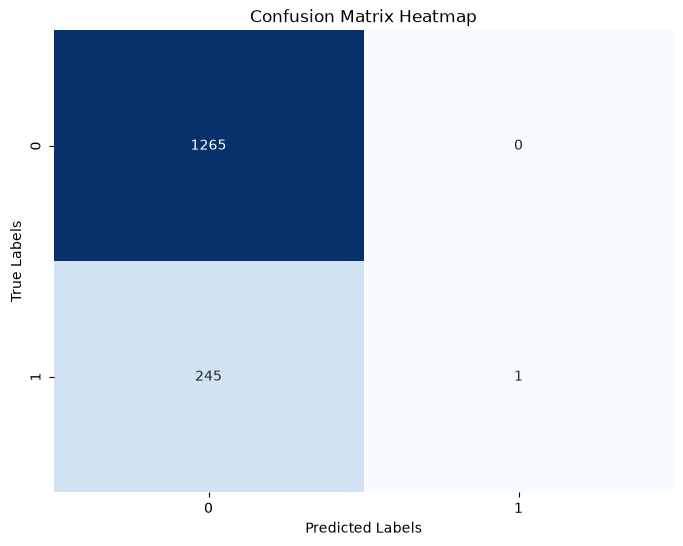

In [23]:
accuracy = accuracy_score(test_Y, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(test_Y, y_pred)

labels = sorted(df.modified.unique())

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, 
            xticklabels=labels, yticklabels=labels)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [26]:
#adding class weight argument 

classifier = RandomForestClassifier(n_estimators=100, random_state=42, class_weight = "balanced")
classifier.fit(train_X, train_Y)
y_pred = classifier.predict(test_X)


Accuracy: 80.34%


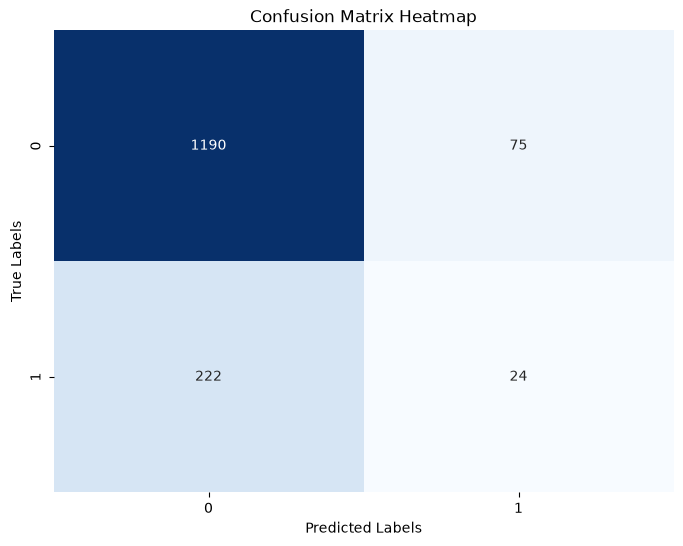

In [27]:
accuracy = accuracy_score(test_Y, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(test_Y, y_pred)

labels = sorted(df.modified.unique())

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, 
            xticklabels=labels, yticklabels=labels)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

## plotting feature importance 

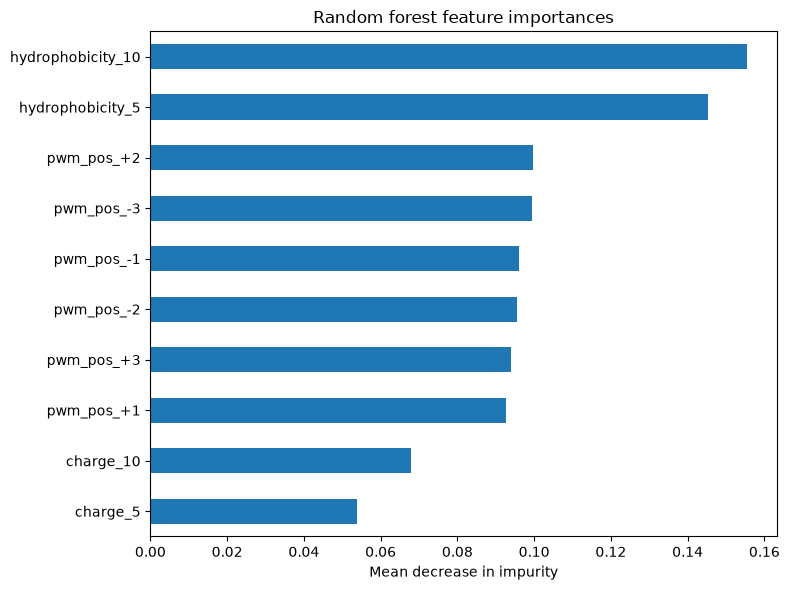

In [32]:
importances = pd.Series(classifier.feature_importances_, index=feature_cols)
top = importances.sort_values(ascending=True).tail(20)  # top 20, largest at the top of the plot

plt.figure(figsize=(8, 6))
top.plot(kind='barh')
plt.xlabel('Mean decrease in impurity')
plt.title('Random forest feature importances')
plt.tight_layout()
plt.show()